# Mouse-level inference for reaction time and prior-choice congruency

This companion notebook adds uncertainty estimates and formal inference to the descriptive analysis in `reaction_time_analysis.ipynb`. It does not refresh or download source data.

The independent unit is the mouse. For every contrast, the tested effect is:

$$D_m = RT_{m,\mathrm{incongruent}} - RT_{m,\mathrm{congruent}}$$

Positive values mean that incongruent choices were initiated more slowly. All tests are two-sided because the descriptive results were inspected before the inferential procedure was fixed. The three primary contrasts are treated as one testing family and corrected with Holm's method.


## 0. Configuration


In [1]:
from __future__ import annotations

from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest, friedmanchisquare, wilcoxon

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name in {"notebooks", "colab"}:
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "reaction_time_trials.parquet"
SAVED_MOUSE_PATH = PROJECT_ROOT / "results" / "02_each_mouse" / "mouse_summary.csv"
OUTPUT_DIR = PROJECT_ROOT / "results" / "04_inference"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CONTRASTS = (0.0, 0.0625, 0.125)
CONTRAST_LABELS = {0.0: "0%", 0.0625: "6.25%", 0.125: "12.5%"}
LABEL_ORDER = [CONTRAST_LABELS[value] for value in CONTRASTS]
RANDOM_SEED = 2026
N_BOOTSTRAP = 20_000
ALPHA = 0.05
DIFFERENCE_COLOR = "#8a63d2"
SENSITIVITY_COLOR = "#d17b2f"

assert DATA_PATH.exists(), f"Missing processed trials: {DATA_PATH}"
assert SAVED_MOUSE_PATH.exists(), f"Run reaction_time_analysis.ipynb first: {SAVED_MOUSE_PATH}"
print(f"Project root: {PROJECT_ROOT}")
print(f"Bootstrap: {N_BOOTSTRAP:,} mouse resamples; seed={RANDOM_SEED}")


Project root: /Users/default/Desktop/study/CompN/compneuro-course-content-main/team-tbd
Bootstrap: 20,000 mouse resamples; seed=2026


## 1. Load and validate the committed trial table

Reaction time is recomputed from the timestamps and checked against the saved values. Primary inference includes every valid completed choice, whether correct or incorrect.


In [2]:
trials = pd.read_parquet(DATA_PATH)

assert trials["eid"].nunique() == 459
assert trials["subject"].nunique() == 139
assert len(trials) == 89_931
assert int(trials["valid_rt"].sum()) == 89_871
assert set(np.round(trials["contrast"].unique(), 4)) == set(CONTRASTS)
assert trials["congruency"].isin(["congruent", "incongruent"]).all()
assert np.allclose(
    trials["reaction_time_ms"],
    1000.0 * (trials["firstMovement_times"] - trials["stimOn_times"]),
    equal_nan=True,
)

valid_values = trials.loc[trials["valid_rt"], "reaction_time_ms"]
assert valid_values.gt(0).all() and valid_values.le(2000).all()

print(f"Processed rows: {len(trials):,}")
print(f"Valid RT rows: {int(trials['valid_rt'].sum()):,}")
print(f"Sessions: {trials['eid'].nunique()} | mice: {trials['subject'].nunique()}")


Processed rows: 89,931
Valid RT rows: 89,871
Sessions: 459 | mice: 139


## 2. Reconstruct paired session and mouse summaries

Within each session and condition, the typical RT is the trial median:

$$M_{s,k,g}=\operatorname{median}(RT_{s,k,g})$$

Session differences are $M_{s,k,I}-M_{s,k,C}$, and these paired session differences are averaged within each mouse. A correct-only session is retained only when both congruency conditions exist; incomplete pairs are counted explicitly.


In [3]:
def build_paired_summaries(
    frame: pd.DataFrame,
    *,
    correct_only: bool,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    analysis = frame.loc[frame["valid_rt"]].copy()
    if correct_only:
        analysis = analysis.loc[analysis["correct"]].copy()

    condition = (
        analysis.groupby(
            ["eid", "subject", "contrast", "contrast_label", "congruency"],
            observed=True,
        )["reaction_time_ms"]
        .agg(n_trials="size", median_rt_ms="median")
        .reset_index()
    )

    pair_counts = condition.groupby(["eid", "contrast", "contrast_label"], observed=True)["congruency"].nunique()
    complete_keys = pair_counts.loc[pair_counts.eq(2)].reset_index()[["eid", "contrast", "contrast_label"]]
    complete_condition = condition.merge(
        complete_keys,
        on=["eid", "contrast", "contrast_label"],
        how="inner",
        validate="many_to_one",
    )

    session_summary = complete_condition.pivot(
        index=["eid", "subject", "contrast", "contrast_label"],
        columns="congruency",
        values=["n_trials", "median_rt_ms"],
    ).reset_index()
    session_summary.columns = [
        "_".join(str(part) for part in column if str(part)) if isinstance(column, tuple) else column
        for column in session_summary.columns
    ]
    session_summary = session_summary.rename(columns={
        "n_trials_congruent": "congruent_n",
        "n_trials_incongruent": "incongruent_n",
        "median_rt_ms_congruent": "congruent_median_rt_ms",
        "median_rt_ms_incongruent": "incongruent_median_rt_ms",
    })
    session_summary["difference_ms"] = (
        session_summary["incongruent_median_rt_ms"]
        - session_summary["congruent_median_rt_ms"]
    )

    mouse_summary = (
        session_summary.groupby(["subject", "contrast", "contrast_label"], observed=True)
        .agg(
            n_sessions=("eid", "nunique"),
            congruent_rt_ms=("congruent_median_rt_ms", "mean"),
            incongruent_rt_ms=("incongruent_median_rt_ms", "mean"),
            difference_ms=("difference_ms", "mean"),
        )
        .reset_index()
    )

    all_pairs = frame[["eid", "subject", "contrast", "contrast_label"]].drop_duplicates()
    complete_with_subject = complete_keys.merge(
        all_pairs,
        on=["eid", "contrast", "contrast_label"],
        how="left",
        validate="one_to_one",
    )
    coverage_rows = []
    for contrast in CONTRASTS:
        label = CONTRAST_LABELS[contrast]
        total = all_pairs.loc[np.isclose(all_pairs["contrast"], contrast)]
        complete = complete_with_subject.loc[np.isclose(complete_with_subject["contrast"], contrast)]
        covered_mice = int(complete["subject"].nunique())
        coverage_rows.append({
            "contrast": label,
            "total_sessions": int(total["eid"].nunique()),
            "complete_sessions": int(complete["eid"].nunique()),
            "incomplete_sessions": int(total["eid"].nunique() - complete["eid"].nunique()),
            "total_mice": int(total["subject"].nunique()),
            "covered_mice": covered_mice,
            "excluded_mice": int(total["subject"].nunique() - covered_mice),
        })

    coverage = pd.DataFrame(coverage_rows)
    return session_summary, mouse_summary, coverage


primary_sessions, primary_mice, primary_coverage = build_paired_summaries(
    trials,
    correct_only=False,
)
correct_sessions, correct_mice, correct_coverage = build_paired_summaries(
    trials,
    correct_only=True,
)

saved_mice = pd.read_csv(SAVED_MOUSE_PATH)
sort_columns = ["subject", "contrast"]
comparison_columns = [
    "subject", "contrast", "contrast_label", "n_sessions",
    "congruent_rt_ms", "incongruent_rt_ms", "difference_ms",
]
pd.testing.assert_frame_equal(
    primary_mice[comparison_columns].sort_values(sort_columns).reset_index(drop=True),
    saved_mice[comparison_columns].sort_values(sort_columns).reset_index(drop=True),
    check_exact=False,
    rtol=1e-12,
    atol=1e-12,
)

assert primary_coverage["complete_sessions"].tolist() == [459, 459, 459]
assert correct_coverage["complete_sessions"].tolist() == [396, 458, 459]
assert correct_coverage["incomplete_sessions"].tolist() == [63, 1, 0]
assert correct_coverage["covered_mice"].tolist() == [132, 139, 139]
assert correct_coverage["excluded_mice"].tolist() == [7, 0, 0]

print("All-choice reconstruction exactly matches the descriptive notebook output.")
display(correct_coverage)


All-choice reconstruction exactly matches the descriptive notebook output.


,contrast,total_sessions,complete_sessions,incomplete_sessions,total_mice,covered_mice,excluded_mice
0,0%,459,396,63,139,132,7
1,6.25%,459,458,1,139,139,0
2,12.5%,459,459,0,139,139,0


## 3. Primary mouse-level inference

The percentile bootstrap resamples whole mice, never individual trials or sessions. The exact sign test evaluates whether positive and negative mouse effects are balanced under $P(D_m>0)=0.5$. Exact zero differences are reported and excluded from that binomial denominator. Holm adjustment controls the family of three contrast tests.


In [4]:
def holm_adjust(p_values: np.ndarray) -> np.ndarray:
    values = np.asarray(p_values, dtype=float)
    order = np.argsort(values)
    ordered = values[order]
    factors = len(values) - np.arange(len(values))
    adjusted_ordered = np.maximum.accumulate(ordered * factors)
    adjusted_ordered = np.clip(adjusted_ordered, 0.0, 1.0)
    adjusted = np.empty_like(adjusted_ordered)
    adjusted[order] = adjusted_ordered
    return adjusted


def percentile_bootstrap_median(
    values: np.ndarray,
    *,
    rng: np.random.Generator,
    n_resamples: int = N_BOOTSTRAP,
) -> tuple[float, float]:
    clean = np.asarray(values, dtype=float)
    assert clean.ndim == 1 and len(clean) > 1 and np.isfinite(clean).all()
    indices = rng.integers(0, len(clean), size=(n_resamples, len(clean)))
    bootstrap_medians = np.median(clean[indices], axis=1)
    low, high = np.quantile(bootstrap_medians, [0.025, 0.975])
    return float(low), float(high)


def run_sign_inference(
    mouse_summary: pd.DataFrame,
    *,
    seed: int = RANDOM_SEED,
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []
    for contrast in CONTRASTS:
        label = CONTRAST_LABELS[contrast]
        values = mouse_summary.loc[
            np.isclose(mouse_summary["contrast"], contrast),
            "difference_ms",
        ].to_numpy(dtype=float)
        positive = int(np.sum(values > 0))
        negative = int(np.sum(values < 0))
        zero = int(np.sum(values == 0))
        assert positive + negative + zero == len(values)
        ci_low, ci_high = percentile_bootstrap_median(values, rng=rng)
        p_value = float(binomtest(
            positive,
            n=positive + negative,
            p=0.5,
            alternative="two-sided",
        ).pvalue)
        rows.append({
            "contrast": label,
            "n_mice": int(len(values)),
            "n_positive": positive,
            "n_negative": negative,
            "n_zero": zero,
            "median_difference_ms": float(np.median(values)),
            "mean_difference_ms": float(np.mean(values)),
            "ci95_low_ms": ci_low,
            "ci95_high_ms": ci_high,
            "sign_p_raw": p_value,
        })

    output = pd.DataFrame(rows)
    output["sign_p_holm"] = holm_adjust(output["sign_p_raw"].to_numpy())
    output["reject_holm_0_05"] = output["sign_p_holm"].lt(ALPHA)
    return output


primary_inference = run_sign_inference(primary_mice)
primary_inference_repeat = run_sign_inference(primary_mice)
pd.testing.assert_frame_equal(primary_inference, primary_inference_repeat)

assert primary_inference["n_mice"].tolist() == [139, 139, 139]
assert primary_inference["n_positive"].tolist() == [95, 103, 111]
assert primary_inference["n_negative"].tolist() == [44, 36, 28]
assert primary_inference["n_zero"].tolist() == [0, 0, 0]
expected_sign_p = np.array([1.8167956227043725e-05, 1.1346454434190287e-08, 6.813312267265689e-13])
assert np.allclose(primary_inference["sign_p_raw"], expected_sign_p, rtol=1e-12, atol=0)

display(primary_inference)


,contrast,n_mice,n_positive,n_negative,n_zero,median_difference_ms,mean_difference_ms,ci95_low_ms,ci95_high_ms,sign_p_raw,sign_p_holm,reject_holm_0_05
0,0%,139,95,44,0,20.112558,52.609088,12.350000,26.125329,1.816796e-05,1.816796e-05,True
1,6.25%,139,103,36,0,18.677853,38.527047,12.114316,23.066667,1.134645e-08,2.269291e-08,True
2,12.5%,139,111,28,0,13.976272,27.152413,10.795057,19.524634,6.813312e-13,2.043994e-12,True


## 4. Correct-only sensitivity analysis

This is secondary because conditioning on correctness changes the scientific question. At 0%, seven mice have no session containing both correct congruent and correct incongruent trials; they are explicitly absent from that sensitivity estimate.


In [5]:
correct_only_inference = run_sign_inference(correct_mice)
correct_only_inference = correct_only_inference.merge(
    correct_coverage,
    on="contrast",
    how="left",
    validate="one_to_one",
)

assert correct_only_inference["n_mice"].tolist() == [132, 139, 139]
assert np.allclose(
    correct_only_inference["median_difference_ms"],
    [46.49196008388874, 21.476235458123938, 13.46666620772794],
    rtol=1e-10,
    atol=1e-10,
)
display(correct_only_inference)


,contrast,n_mice,n_positive,n_negative,n_zero,median_difference_ms,mean_difference_ms,ci95_low_ms,ci95_high_ms,sign_p_raw,sign_p_holm,reject_holm_0_05,total_sessions,complete_sessions,incomplete_sessions,total_mice,covered_mice,excluded_mice
0,0%,132,100,32,0,46.491960,98.521489,34.197574,73.109727,2.428470e-09,4.856939e-09,True,459,396,63,139,132,7
1,6.25%,139,102,37,0,21.476235,48.288217,12.956218,30.495084,3.220003e-08,3.220003e-08,True,459,458,1,139,139,0
2,12.5%,139,107,32,0,13.466666,22.285430,8.708038,18.652663,1.206928e-10,3.620784e-10,True,459,459,0,139,139,0


## 5. Does the effect differ across contrasts?

A Friedman test provides a repeated-measures omnibus comparison of the three mouse effects. Only if that omnibus test is below 0.05 are the three paired Wilcoxon comparisons interpreted; those follow-ups use their own Holm correction. A positive pairwise estimate means that the first named contrast has the larger $I-C$ effect.


In [6]:
def run_contrast_tests(mouse_summary: pd.DataFrame) -> pd.DataFrame:
    paired = (
        mouse_summary.pivot(index="subject", columns="contrast_label", values="difference_ms")
        .reindex(columns=LABEL_ORDER)
        .sort_index()
    )
    assert paired.shape == (139, 3) and paired.notna().all().all()

    friedman = friedmanchisquare(*(paired[label].to_numpy() for label in LABEL_ORDER))
    rows = [{
        "test": "Friedman omnibus",
        "comparison": "0% vs 6.25% vs 12.5%",
        "n_mice": len(paired),
        "estimate_median_ms": np.nan,
        "ci95_low_ms": np.nan,
        "ci95_high_ms": np.nan,
        "statistic": float(friedman.statistic),
        "p_raw": float(friedman.pvalue),
        "p_holm": float(friedman.pvalue),
        "reject_holm_0_05": bool(friedman.pvalue < ALPHA),
    }]

    if friedman.pvalue < ALPHA:
        rng = np.random.default_rng(RANDOM_SEED)
        followups = []
        for first, second in combinations(LABEL_ORDER, 2):
            difference = paired[first].to_numpy() - paired[second].to_numpy()
            ci_low, ci_high = percentile_bootstrap_median(difference, rng=rng)
            test = wilcoxon(
                paired[first].to_numpy(),
                paired[second].to_numpy(),
                alternative="two-sided",
                zero_method="wilcox",
                method="auto",
            )
            followups.append({
                "test": "Wilcoxon paired",
                "comparison": f"{first} minus {second}",
                "n_mice": len(paired),
                "estimate_median_ms": float(np.median(difference)),
                "ci95_low_ms": ci_low,
                "ci95_high_ms": ci_high,
                "statistic": float(test.statistic),
                "p_raw": float(test.pvalue),
            })
        adjusted = holm_adjust(np.array([row["p_raw"] for row in followups]))
        for row, p_holm in zip(followups, adjusted):
            row["p_holm"] = float(p_holm)
            row["reject_holm_0_05"] = bool(p_holm < ALPHA)
        rows.extend(followups)

    return pd.DataFrame(rows)


contrast_effect_tests = run_contrast_tests(primary_mice)
display(contrast_effect_tests)


,test,comparison,n_mice,estimate_median_ms,ci95_low_ms,ci95_high_ms,statistic,p_raw,p_holm,reject_holm_0_05
0,Friedman omnibus,0% vs 6.25% vs 12.5%,139,NaN,NaN,NaN,1.683453,0.430966,0.430966,False


## 6. Save abstract-ready tables and figures

The first figure retains every positive and negative mouse effect and overlays the median with its 95% bootstrap CI. The sensitivity figure compares the primary all-choice estimate with the correct-only estimate; it is not a replacement primary analysis.


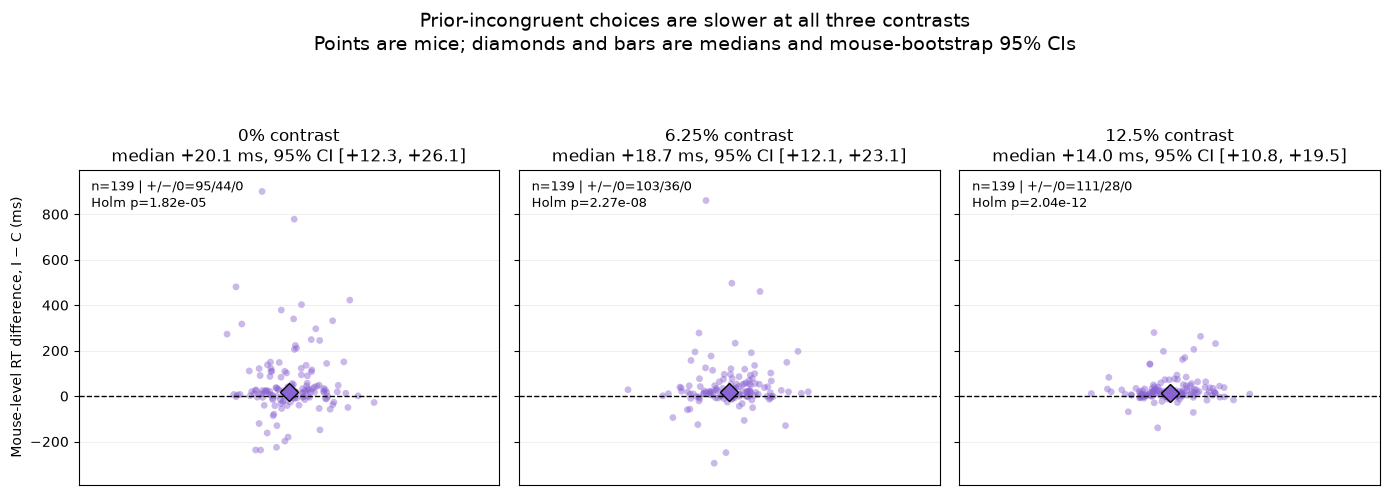

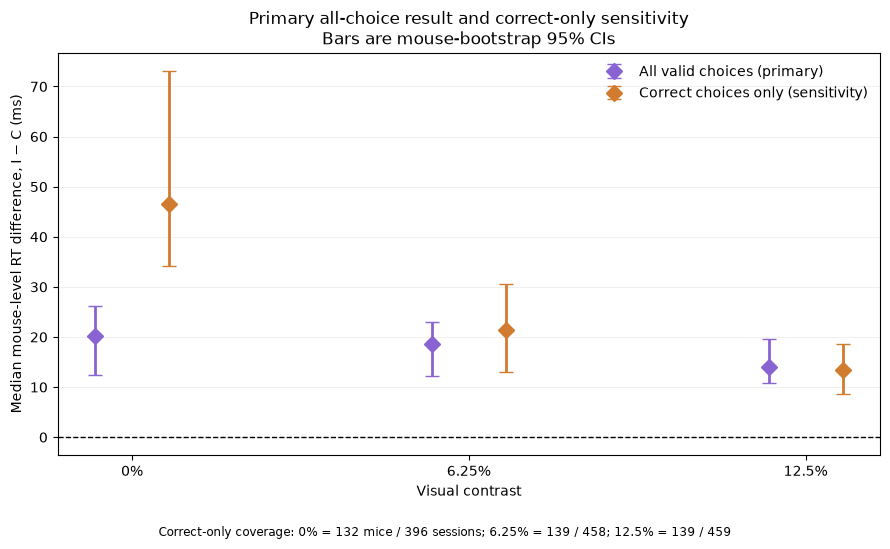

In [7]:
primary_inference.to_csv(OUTPUT_DIR / "primary_inference.csv", index=False)
correct_only_inference.to_csv(OUTPUT_DIR / "correct_only_inference.csv", index=False)
correct_coverage.to_csv(OUTPUT_DIR / "correct_only_coverage.csv", index=False)
contrast_effect_tests.to_csv(OUTPUT_DIR / "contrast_effect_tests.csv", index=False)

rng = np.random.default_rng(RANDOM_SEED)
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)
all_values = primary_mice["difference_ms"].to_numpy()
y_padding = 0.08 * (all_values.max() - all_values.min())
y_limits = (all_values.min() - y_padding, all_values.max() + y_padding)
for axis, contrast, row in zip(axes, CONTRASTS, primary_inference.to_dict("records")):
    values = primary_mice.loc[np.isclose(primary_mice["contrast"], contrast), "difference_ms"].to_numpy()
    jitter = rng.normal(0, 0.045, len(values))
    axis.axhline(0, color="black", linestyle="--", linewidth=1)
    axis.scatter(jitter, values, s=24, alpha=0.45, color=DIFFERENCE_COLOR, edgecolors="none")
    median = row["median_difference_ms"]
    low = row["ci95_low_ms"]
    high = row["ci95_high_ms"]
    axis.errorbar(
        [0], [median], yerr=[[median - low], [high - median]],
        fmt="D", markersize=9, color="black", markerfacecolor=DIFFERENCE_COLOR,
        capsize=6, linewidth=2.2, zorder=5,
    )
    axis.set(
        title=(f"{row['contrast']} contrast\n"
               f"median {median:+.1f} ms, 95% CI [{low:+.1f}, {high:+.1f}]"),
        xlim=(-0.35, 0.35),
        ylim=y_limits,
        xticks=[],
    )
    axis.text(
        0.03, 0.97,
        f"n={row['n_mice']} | +/−/0={row['n_positive']}/{row['n_negative']}/{row['n_zero']}\n"
        f"Holm p={row['sign_p_holm']:.2e}",
        transform=axis.transAxes, va="top", fontsize=9,
    )
    axis.grid(axis="y", alpha=0.18)
axes[0].set_ylabel("Mouse-level RT difference, I − C (ms)")
fig.suptitle("Prior-incongruent choices are slower at all three contrasts\nPoints are mice; diamonds and bars are medians and mouse-bootstrap 95% CIs", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.savefig(OUTPUT_DIR / "primary_effect_ci.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axis = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(LABEL_ORDER), dtype=float)
for offset, table, label, color in [
    (-0.11, primary_inference, "All valid choices (primary)", DIFFERENCE_COLOR),
    (0.11, correct_only_inference, "Correct choices only (sensitivity)", SENSITIVITY_COLOR),
]:
    median = table["median_difference_ms"].to_numpy()
    low = table["ci95_low_ms"].to_numpy()
    high = table["ci95_high_ms"].to_numpy()
    axis.errorbar(
        x + offset, median,
        yerr=np.vstack([median - low, high - median]),
        fmt="D", markersize=8, capsize=5, linewidth=2,
        color=color, label=label,
    )
axis.axhline(0, color="black", linestyle="--", linewidth=1)
axis.set(
    xticks=x,
    xticklabels=LABEL_ORDER,
    xlabel="Visual contrast",
    ylabel="Median mouse-level RT difference, I − C (ms)",
    title="Primary all-choice result and correct-only sensitivity\nBars are mouse-bootstrap 95% CIs",
)
axis.grid(axis="y", alpha=0.18)
axis.legend(frameon=False)
fig.text(
    0.5, 0.015,
    "Correct-only coverage: 0% = 132 mice / 396 sessions; 6.25% = 139 / 458; 12.5% = 139 / 459",
    ha="center", fontsize=8.5,
)
fig.tight_layout(rect=(0, 0.055, 1, 1))
fig.savefig(OUTPUT_DIR / "correct_only_sensitivity.png", dpi=180, bbox_inches="tight")
plt.show()


## 7. Generate the report and enforce reporting rules

Statistical significance is based on the Holm-adjusted two-sided p-value. Every claim includes the effect estimate and confidence interval. Contrast-dependent wording is permitted only when supported by the repeated-measures tests.


In [8]:
def effect_sentence(row: pd.Series) -> str:
    status = "statistically significant" if row["reject_holm_0_05"] else "not statistically significant"
    return (
        f"- **{row['contrast']} contrast:** median I−C {row['median_difference_ms']:+.1f} ms "
        f"(95% mouse-bootstrap CI {row['ci95_low_ms']:+.1f} to {row['ci95_high_ms']:+.1f} ms; "
        f"{int(row['n_positive'])}/{int(row['n_mice'])} positive mice; "
        f"two-sided exact sign test Holm-adjusted p={row['sign_p_holm']:.3g}); {status}."
    )


primary_lines = "\n".join(effect_sentence(row) for _, row in primary_inference.iterrows())
sensitivity_lines = "\n".join(effect_sentence(row) for _, row in correct_only_inference.iterrows())
omnibus = contrast_effect_tests.iloc[0]
if omnibus["reject_holm_0_05"]:
    contrast_text = (
        f"The repeated-measures Friedman test detected a contrast-dependent difference "
        f"(χ²={omnibus['statistic']:.2f}, p={omnibus['p_raw']:.3g}). "
        "Only Holm-significant paired follow-ups justify specific contrast comparisons."
    )
else:
    contrast_text = (
        f"The repeated-measures Friedman test did not detect a contrast-dependent difference "
        f"(χ²={omnibus['statistic']:.2f}, p={omnibus['p_raw']:.3g}); the abstract must not claim that the effect changes with contrast."
    )

report = f"""# Reaction-time inference results

## Methods

The independent unit was the mouse. Trial RTs were summarized by the median within each session, contrast, and congruency condition; paired session differences were averaged within mouse. For each contrast, the median mouse-level incongruent-minus-congruent difference received a 95% percentile bootstrap confidence interval from {N_BOOTSTRAP:,} whole-mouse resamples (seed {RANDOM_SEED}). Directional consistency was tested with a two-sided exact sign test, with Holm correction across the three co-primary contrasts. These procedures were specified after descriptive inspection and were not preregistered.

## Primary all-choice results

{primary_lines}

## Correct-only sensitivity

{sensitivity_lines}

At 0%, seven mice were excluded because none of their sessions contained both correct congruent and correct incongruent trials. This sensitivity analysis changes the estimand and does not replace the primary all-choice result.

## Contrast dependence

{contrast_text}

See `contrast_effect_tests.csv` for the omnibus and Holm-adjusted paired comparisons.

## Abstract-ready interpretation

Across 139 mice, choices opposing the current block prior were associated with slower movement initiation at 0%, 6.25%, and 12.5% visual contrast. Report the contrast-specific median effects, 95% CIs, and Holm-adjusted p-values above. The result is associative rather than causal, and the correct-only analysis is a secondary sensitivity analysis.

## Reporting limitations

- The analysis was specified after the descriptive results were inspected and was not preregistered.
- Correctness differs between congruency groups; the correct-only sensitivity changes the target population and has reduced 0% coverage.
- Trial counts are unequal, sessions receive equal weight within mouse, and mice receive equal cohort weight.
- No trial-level mixed-effects model is included in this robust-core analysis.
"""
(OUTPUT_DIR / "README.md").write_text(report, encoding="utf-8")
print(report)


# Reaction-time inference results

## Methods

The independent unit was the mouse. Trial RTs were summarized by the median within each session, contrast, and congruency condition; paired session differences were averaged within mouse. For each contrast, the median mouse-level incongruent-minus-congruent difference received a 95% percentile bootstrap confidence interval from 20,000 whole-mouse resamples (seed 2026). Directional consistency was tested with a two-sided exact sign test, with Holm correction across the three co-primary contrasts. These procedures were specified after descriptive inspection and were not preregistered.

## Primary all-choice results

- **0% contrast:** median I−C +20.1 ms (95% mouse-bootstrap CI +12.3 to +26.1 ms; 95/139 positive mice; two-sided exact sign test Holm-adjusted p=1.82e-05); statistically significant.
- **6.25% contrast:** median I−C +18.7 ms (95% mouse-bootstrap CI +12.1 to +23.1 ms; 103/139 positive mice; two-sided exact sign test Holm-adjusted

## 8. Final reproducibility checks

These checks make the inferential outputs fail loudly if the cohort, pairing, signs, coverage, or saved files change unexpectedly.


In [9]:
expected_outputs = [
    OUTPUT_DIR / "primary_inference.csv",
    OUTPUT_DIR / "correct_only_inference.csv",
    OUTPUT_DIR / "correct_only_coverage.csv",
    OUTPUT_DIR / "contrast_effect_tests.csv",
    OUTPUT_DIR / "primary_effect_ci.png",
    OUTPUT_DIR / "correct_only_sensitivity.png",
    OUTPUT_DIR / "README.md",
]
for path in expected_outputs:
    assert path.exists() and path.stat().st_size > 0, f"Missing or empty output: {path}"

assert (primary_inference[["n_positive", "n_negative", "n_zero"]].sum(axis=1) == 139).all()
assert primary_inference["reject_holm_0_05"].all()
assert (primary_inference["sign_p_holm"] >= primary_inference["sign_p_raw"]).all()
assert correct_only_inference["covered_mice"].tolist() == [132, 139, 139]

print("Inference analysis complete")
print("  all-choice reconstruction verified")
print("  3 primary mouse-bootstrap CIs and Holm-adjusted sign tests")
print("  correct-only sensitivity with explicit coverage")
print("  repeated-measures contrast analysis")
print(f"  {len(expected_outputs)} saved inference outputs")


Inference analysis complete
  all-choice reconstruction verified
  3 primary mouse-bootstrap CIs and Holm-adjusted sign tests
  correct-only sensitivity with explicit coverage
  repeated-measures contrast analysis
  7 saved inference outputs
